# Visualisasi Data Harga Rumah Bandung

Notebook ini memvisualisasikan `dataset_rumah_bandung_cleaned.csv` untuk :

**Daftar section**
- Section 1 – Import library & upload data
- Section 2 – Histogram harga
- Section 3 – Bar chart median harga per lokasi
- Section 4 – Scatter plot harga vs luas bangunan

## Section 1 – Import Library & Upload Data

In [30]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:,.2f}".format)

### 1.1 Upload file CSV
Jalankan sel di bawah, lalu pilih file `dataset_rumah_bandung_cleaned.csv` dari komputer.

In [31]:
uploaded = files.upload()

nama_file = list(uploaded.keys())[0]
print(f"\nFile terbaca: {nama_file}")

df = pd.read_csv(io.BytesIO(uploaded[nama_file]))
print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")

Saving dataset_rumah_bandung_cleaned.csv to dataset_rumah_bandung_cleaned (6).csv

File terbaca: dataset_rumah_bandung_cleaned (6).csv
Jumlah baris : 6,992
Jumlah kolom : 8


### 1.2 Pengecekan kolom
Memastikan semua kolom yang dibutuhkan ada, tipe datanya benar, dan melihat apakah ada nilai kosong atau duplikat.

In [32]:
kolom_diharapkan = [
    "house_name", "location", "bedroom_count", "bathroom_count",
    "carport_count", "price", "land_area", "building_area",
]

print("Kolom di file :", list(df.columns))
hilang = [k for k in kolom_diharapkan if k not in df.columns]
tambahan = [k for k in df.columns if k not in kolom_diharapkan]
print("Kolom hilang  :", hilang if hilang else "tidak ada")
print("Kolom tambahan:", tambahan if tambahan else "tidak ada")
assert not hilang, f"Kolom berikut tidak ditemukan: {hilang}"

print("\n=== Info tipe data & nilai non-null ===")
df.info()

print("\n=== Nilai kosong per kolom ===")
print(df.isna().sum())
print(f"\nBaris duplikat: {df.duplicated().sum()}")

Kolom di file : ['house_name', 'location', 'bedroom_count', 'bathroom_count', 'carport_count', 'price', 'land_area', 'building_area']
Kolom hilang  : tidak ada
Kolom tambahan: tidak ada

=== Info tipe data & nilai non-null ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6992 entries, 0 to 6991
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   house_name      6992 non-null   object
 1   location        6992 non-null   object
 2   bedroom_count   6992 non-null   int64 
 3   bathroom_count  6992 non-null   int64 
 4   carport_count   6992 non-null   int64 
 5   price           6992 non-null   int64 
 6   land_area       6992 non-null   int64 
 7   building_area   6992 non-null   int64 
dtypes: int64(6), object(2)
memory usage: 437.1+ KB

=== Nilai kosong per kolom ===
house_name        0
location          0
bedroom_count     0
bathroom_count    0
carport_count     0
price             0
land_area         0
bui

In [33]:
# Pratinjau data dan ringkasan statistik
display(df.head())
display(df.describe().T)

,house_name,location,bedroom_count,bathroom_count,carport_count,price,land_area,building_area
0,Rumah 2 Lantai Bagus Sertifikat Hak Milik di M...,"Andir, Bandung",3,2,2,2100000000,137,170
1,Rumah Cantik @ Andir (Sudirman),"Andir, Bandung",3,2,3,4100000000,202,300
2,Jual Cepat Rumah di Maleber Rajawali Bisa Untu...,"Andir, Bandung",5,2,1,3300000000,350,258
3,Rumah minimalis 3 lantai di andir Bandung coco...,"Andir, Bandung",2,2,1,580000000,30,80
4,Jual Rumah Murah Bisa Dijadikan Kos”an Di Jala...,"Andir, Bandung",11,3,0,1300000000,176,176


,count,mean,std,min,25%,50%,75%,max
bedroom_count,"6,992.00",4.51,4.80,0.00,3.00,4.00,5.00,99.00
bathroom_count,"6,992.00",3.20,4.18,0.00,2.00,3.00,3.00,99.00
carport_count,"6,992.00",1.40,1.97,0.00,0.00,1.00,2.00,40.00
price,"6,992.00","5,002,817,863.27","15,261,580,125.92","12,000,000.00","1,100,000,000.00","2,200,000,000.00","4,700,000,000.00","735,000,000,000.00"
land_area,"6,992.00",275.26,438.58,6.00,102.00,165.00,312.00,"11,850.00"
building_area,"6,992.00",677.85,"35,947.18",1.00,100.00,180.00,300.00,"3,006,000.00"


In [34]:
# Kolom bantu: harga dalam miliar rupiah agar angka lebih mudah dibaca
df["price_miliar"] = df["price"] / 1e9

# Batas persentil ke-99 (dipakai untuk histogram & scatter plot)
batas_harga = df["price"].quantile(0.99)
batas_bangunan = df["building_area"].quantile(0.99)
print(f"Batas persentil 99 harga          : Rp {batas_harga/1e9:,.1f} miliar")
print(f"Batas persentil 99 luas bangunan  : {batas_bangunan:,.0f} m²")

Batas persentil 99 harga          : Rp 40.0 miliar
Batas persentil 99 luas bangunan  : 1,100 m²


## Section 2 – Histogram Harga

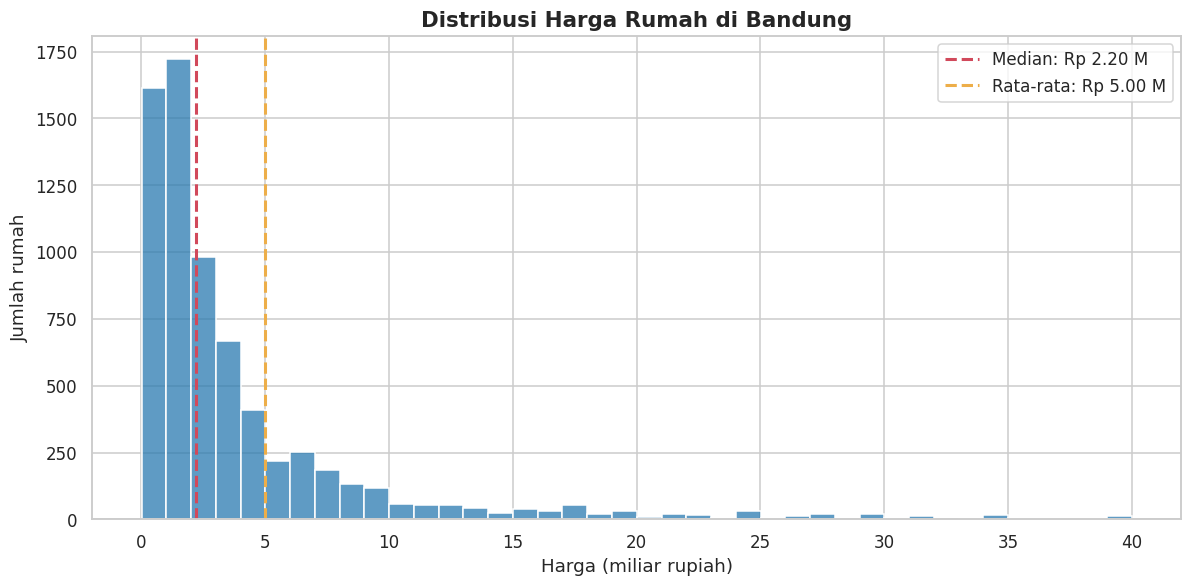

In [35]:
data_hist = df[df["price"] <= batas_harga]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.histplot(data_hist["price_miliar"], bins=40, color="#2a7ab0", edgecolor="white", ax=ax)

median_h = df["price_miliar"].median()
mean_h = df["price_miliar"].mean()
ax.axvline(median_h, color="#d1495b", linestyle="--", linewidth=2, label=f"Median: Rp {median_h:,.2f} M")
ax.axvline(mean_h, color="#edae49", linestyle="--", linewidth=2, label=f"Rata-rata: Rp {mean_h:,.2f} M")

ax.set_title("Distribusi Harga Rumah di Bandung", fontsize=14, fontweight="bold")
ax.set_xlabel("Harga (miliar rupiah)")
ax.set_ylabel("Jumlah rumah")
ax.legend()
plt.tight_layout()
plt.show()

### Rentang harga paling umum
Sel berikut menghitung rentang harga (bin) dengan jumlah rumah terbanyak, serta rentang tempat separuh rumah berada (kuartil 1–3).

In [36]:
# Bin paling padat
counts, edges = np.histogram(data_hist["price_miliar"], bins=40)
i = counts.argmax()
print(f"Rentang harga paling umum : Rp {edges[i]:.2f} – {edges[i+1]:.2f} miliar ({counts[i]:,} rumah)")

# Rentang kuartil (50% rumah berada di sini)
q1, q3 = df["price_miliar"].quantile([0.25, 0.75])
print(f"50% rumah berharga antara : Rp {q1:.2f} – {q3:.2f} miliar (Q1–Q3)")
print(f"Median harga              : Rp {median_h:.2f} miliar")
print(f"Rata-rata harga           : Rp {mean_h:.2f} miliar")

# Persentase rumah di bawah beberapa ambang harga
for batas in [1, 2, 3, 5]:
    persen = (df["price_miliar"] <= batas).mean() * 100
    print(f"Rumah dengan harga ≤ Rp {batas} miliar : {persen:.1f}%")

Rentang harga paling umum : Rp 1.01 – 2.01 miliar (1,723 rumah)
50% rumah berharga antara : Rp 1.10 – 4.70 miliar (Q1–Q3)
Median harga              : Rp 2.20 miliar
Rata-rata harga           : Rp 5.00 miliar
Rumah dengan harga ≤ Rp 1 miliar : 23.0%
Rumah dengan harga ≤ Rp 2 miliar : 47.7%
Rumah dengan harga ≤ Rp 3 miliar : 61.8%
Rumah dengan harga ≤ Rp 5 miliar : 77.2%


## Section 3 – Bar Chart Harga per Lokasi

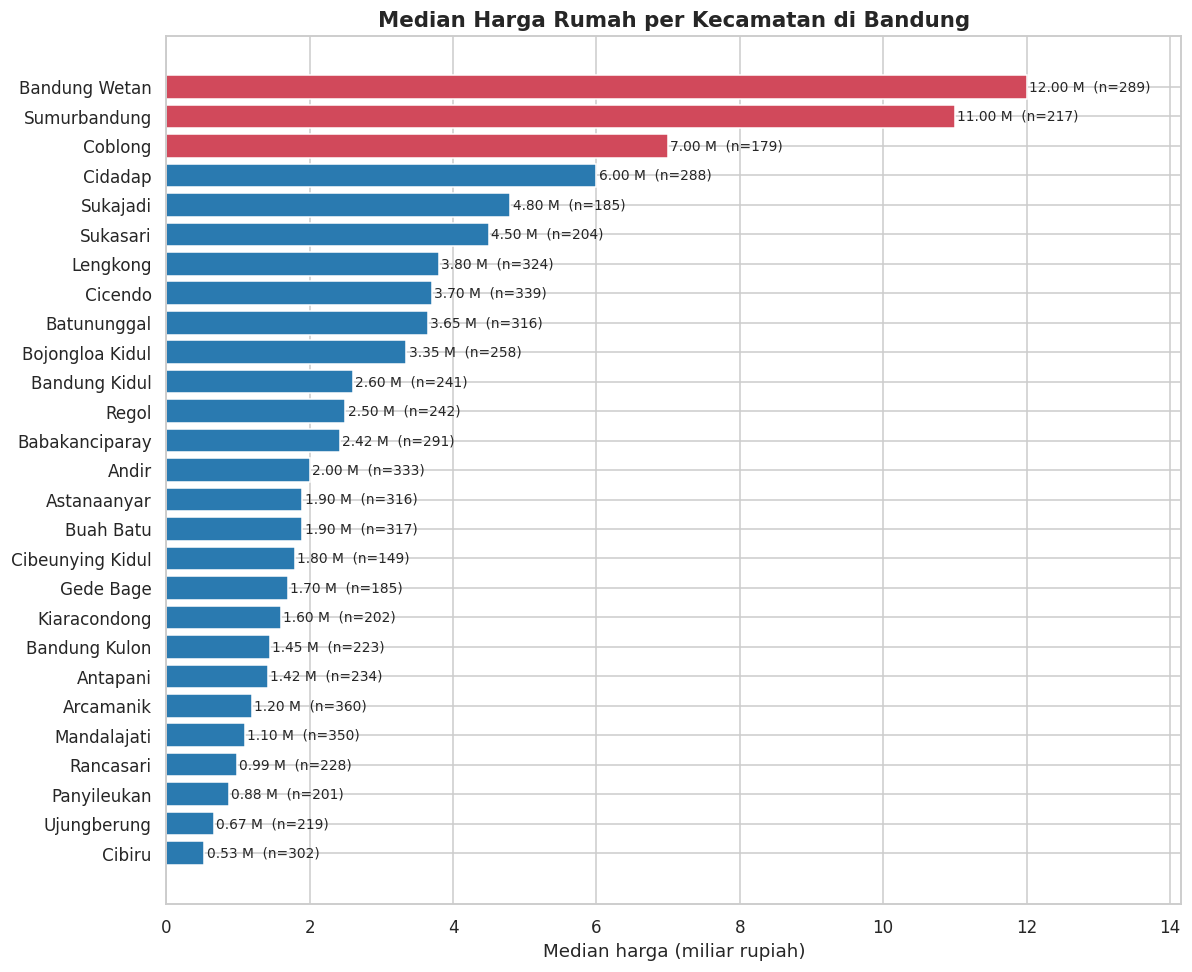

In [37]:
ringkas_lokasi = (
    df.groupby("location")["price_miliar"]
    .agg(median="median", jumlah="count")
    .sort_values("median", ascending=False)
    .reset_index()
)
ringkas_lokasi["wilayah"] = ringkas_lokasi["location"].str.replace(", Bandung", "", regex=False)

# Highlight 3 wilayah dengan median tertinggi
warna = ["#d1495b" if i < 3 else "#2a7ab0" for i in range(len(ringkas_lokasi))]

fig, ax = plt.subplots(figsize=(11, 9))
bars = ax.barh(ringkas_lokasi["wilayah"], ringkas_lokasi["median"], color=warna)
ax.invert_yaxis()  # tertinggi di atas

for bar, med, n in zip(bars, ringkas_lokasi["median"], ringkas_lokasi["jumlah"]):
    ax.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height()/2,
            f"{med:,.2f} M  (n={n})", va="center", fontsize=9)

ax.set_title("Median Harga Rumah per Kecamatan di Bandung", fontsize=14, fontweight="bold")
ax.set_xlabel("Median harga (miliar rupiah)")
ax.set_ylabel("")
ax.set_xlim(0, ringkas_lokasi["median"].max() * 1.18)
plt.tight_layout()
plt.show()

In [38]:
top = ringkas_lokasi.iloc[0]
bottom = ringkas_lokasi.iloc[-1]
print(f"Median tertinggi : {top['wilayah']} – Rp {top['median']:.2f} miliar ({top['jumlah']} rumah)")
print(f"Median terendah  : {bottom['wilayah']} – Rp {bottom['median']:.2f} miliar ({bottom['jumlah']} rumah)")
print(f"Selisih tertinggi vs terendah: {top['median']/bottom['median']:.1f}x")

print("\n=== 5 wilayah dengan median harga tertinggi ===")
display(ringkas_lokasi[["wilayah", "median", "jumlah"]].head(5))

Median tertinggi : Bandung Wetan – Rp 12.00 miliar (289 rumah)
Median terendah  : Cibiru – Rp 0.53 miliar (302 rumah)
Selisih tertinggi vs terendah: 22.6x

=== 5 wilayah dengan median harga tertinggi ===


,wilayah,median,jumlah
0,Bandung Wetan,12.00,289
1,Sumurbandung,11.00,217
2,Coblong,7.00,179
3,Cidadap,6.00,288
4,Sukajadi,4.80,185


## 4. Scatter plot harga vs luas bangunan

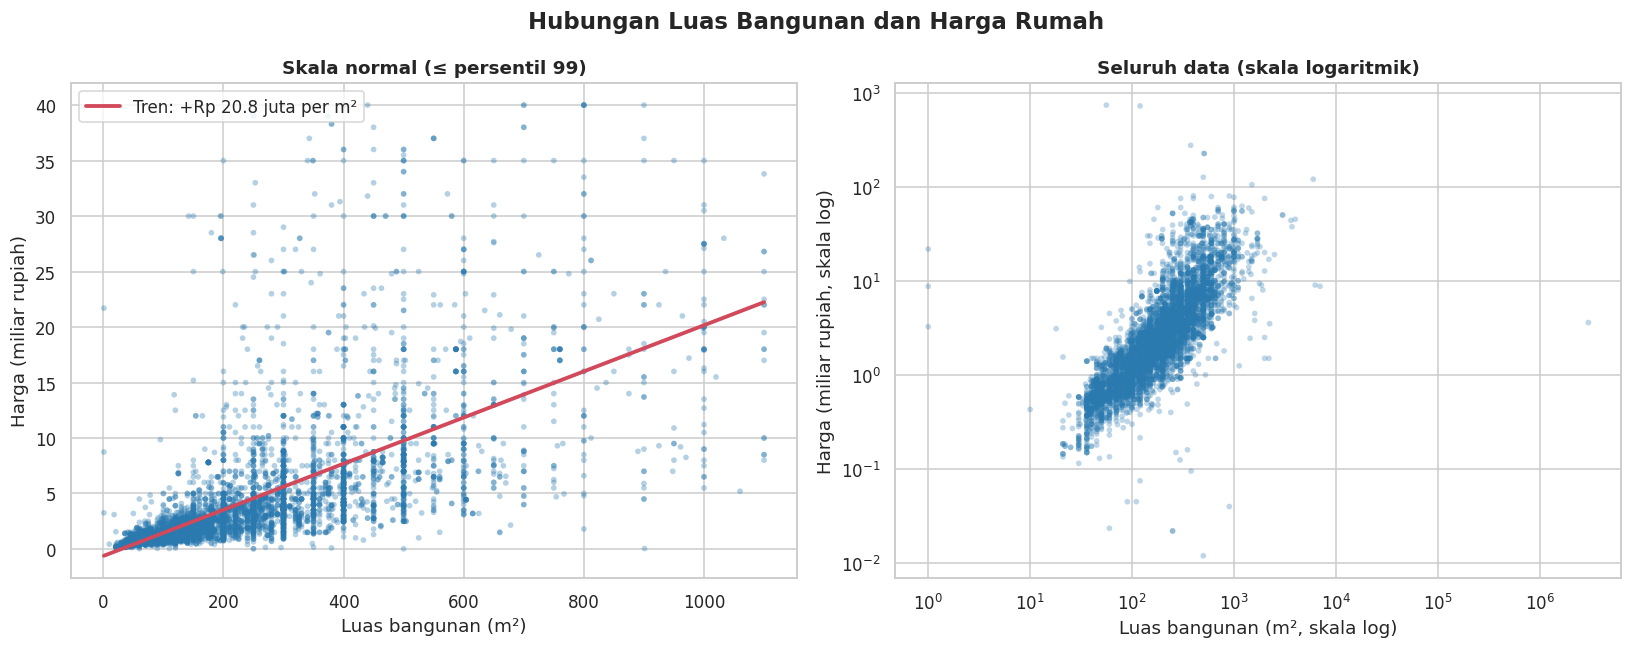

In [39]:
# Data untuk panel kiri: buang outlier ekstrem
data_sc = df[(df["price"] <= batas_harga) & (df["building_area"] <= batas_bangunan)]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Panel kiri: skala normal (tanpa outlier ekstrem) ---
ax = axes[0]
ax.scatter(data_sc["building_area"], data_sc["price_miliar"],
           alpha=0.35, s=14, color="#2a7ab0", edgecolors="none")
slope, intercept = np.polyfit(data_sc["building_area"], data_sc["price_miliar"], 1)
xs = np.linspace(data_sc["building_area"].min(), data_sc["building_area"].max(), 100)
ax.plot(xs, slope * xs + intercept, color="#d1495b", linewidth=2.5,
        label=f"Tren: +Rp {slope*1000:,.1f} juta per m²")
ax.set_title("Skala normal (≤ persentil 99)", fontsize=12, fontweight="bold")
ax.set_xlabel("Luas bangunan (m²)")
ax.set_ylabel("Harga (miliar rupiah)")
ax.legend(loc="upper left")

# --- Panel kanan: semua data, skala log ---
ax = axes[1]
ax.scatter(df["building_area"], df["price_miliar"],
           alpha=0.3, s=14, color="#2a7ab0", edgecolors="none")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Seluruh data (skala logaritmik)", fontsize=12, fontweight="bold")
ax.set_xlabel("Luas bangunan (m², skala log)")
ax.set_ylabel("Harga (miliar rupiah, skala log)")

fig.suptitle("Hubungan Luas Bangunan dan Harga Rumah", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [40]:
pearson_all = df["building_area"].corr(df["price"], method="pearson")
spearman_all = df["building_area"].corr(df["price"], method="spearman")
pearson_f = data_sc["building_area"].corr(data_sc["price"], method="pearson")
spearman_f = data_sc["building_area"].corr(data_sc["price"], method="spearman")

print("=== Korelasi luas bangunan vs harga ===")
print(f"Seluruh data     -> Pearson: {pearson_all:.3f} | Spearman: {spearman_all:.3f}")
print(f"Tanpa outlier    -> Pearson: {pearson_f:.3f} | Spearman: {spearman_f:.3f}")
print(f"Jumlah data tanpa outlier: {len(data_sc):,} dari {len(df):,}")

def kekuatan(r):
    r = abs(r)
    return "sangat lemah" if r < 0.2 else "lemah" if r < 0.4 else "sedang" if r < 0.6 else "kuat" if r < 0.8 else "sangat kuat"

print(f"\nKesimpulan: hubungan positif {kekuatan(spearman_f)} (Spearman = {spearman_f:.2f}), "
      f"rumah dengan bangunan lebih luas cenderung lebih mahal.")

=== Korelasi luas bangunan vs harga ===
Seluruh data     -> Pearson: 0.001 | Spearman: 0.855
Tanpa outlier    -> Pearson: 0.672 | Spearman: 0.854
Jumlah data tanpa outlier: 6,874 dari 6,992

Kesimpulan: hubungan positif sangat kuat (Spearman = 0.85), rumah dengan bangunan lebih luas cenderung lebih mahal.
